# Chapitre 5 - Exercices 5.1 à 5.6

Ce notebook traite les six premiers exercices du chapitre 5, centrés sur la
réplication à leader unique et le retard de réplication :

- **5.1** : latence d'écriture et durabilité selon le mode de réplication (calcul et
  simulation) ;
- **5.2** : monter un suiveur sur une grosse base : copie, rattrapage et rétention du
  journal (calcul) ;
- **5.3** : régler le délai de basculement et trouver l'anomalie d'un basculement
  (raisonnement et calcul) ;
- **5.4** : quelles instructions peut-on répliquer telles quelles ? Rendre la
  réplication par instructions déterministe (mini-lab) ;
- **5.5** : dimensionner « lire ses écritures » : fenêtre au leader contre jeton de
  position (calcul et simulation) ;
- **5.6** : probabilités des anomalies de lectures monotones et de préfixe cohérent
  (calcul et Monte-Carlo).

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 5.1 : latence d'écriture et durabilité

**Énoncé.** Un leader a trois suiveurs. Les allers-retours leader-suiveur suivent des lois
log-normales (écart-type du logarithme 0,3) de médianes : 1 ms pour le suiveur A (même centre de données),
2 ms pour B (autre centre de données de la même ville), 70 ms pour C (centre de données sur un autre continent).
L'écriture locale du leader prend 0,2 ms.

1. Quel suiveur détermine la latence d'écriture en mode asynchrone, semi-synchrone (un
   acquittement), quorum majoritaire (3 nœuds sur 4, leader compris) et tout synchrone ?
   En déduire les latences médianes approximatives.
2. En asynchrone, le leader reçoit 2 000 écritures/s et le suiveur le plus à jour a en
   moyenne 50 ms de retard. Combien d'écritures confirmées perd-on en moyenne lors d'une
   panne franche du leader ? Avec deux pannes de leader par an ?
3. On veut ne jamais perdre une écriture confirmée **et** survivre à la perte d'un centre de données
   entière. Quel mode choisir, et quelle latence en attendre ?

**Rappels.** Le leader attend le $m$-ième plus petit des allers-retours (statistique
d'ordre) ; en asynchrone, une écriture confirmée n'existe que sur le leader tant qu'elle
n'est pas répliquée (cours 1, sections 2 et 5, section *Synchronous Versus Asynchronous
Replication*).

**Solution.**

*1.* Asynchrone : aucun suiveur, latence ≈ 0,2 ms. Semi-synchrone : le **plus rapide**,
presque toujours A, soit ≈ 1,2 ms. Quorum (2 acquittements de suiveurs) : le
**deuxième** plus rapide, presque toujours B, ≈ 2,2 ms. Tout synchrone : le **plus
lent**, C, ≈ 70 ms.

*2.* Les écritures perdues sont celles validées pendant la fenêtre de retard du meilleur
suiveur : $\lambda \times \bar L = 2\,000 \times 0{,}05 = 100$ écritures par panne, soit
environ 200 par an. (Si le suiveur promu n'est pas le plus à jour, davantage.)

*3.* Il faut qu'une écriture confirmée existe **hors du centre de données du leader** : le
semi-synchrone ne suffit pas (l'acquittement vient presque toujours de A, au même
endroit). Le quorum de la question 1 attend A **et** B : B étant dans un autre centre de données, toute
écriture confirmée survit à la perte du centre de données du leader, pour ≈ 2,2 ms. Il faut aussi
que le basculement promeuve un suiveur qui a l'écriture (le plus à jour).

**Vérification par simulation.**

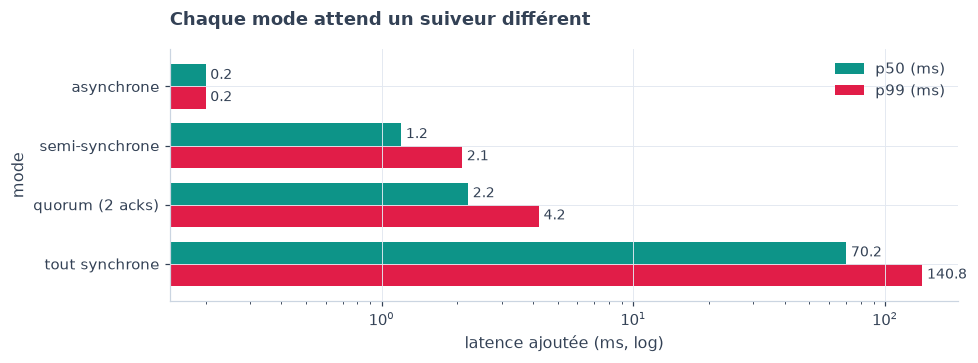

écritures perdues par panne (simulation, retard exponentiel de moyenne 50 ms) : 100


,suiveur déterminant (le plus souvent),p50 (ms),p99 (ms)
mode,,,
asynchrone,aucun,0.20,0.20
semi-synchrone,A,1.20,2.09
quorum (2 acks),B,2.21,4.22
tout synchrone,C,70.19,140.81


In [2]:
n = 200000
med = np.array([1.0, 2.0, 70.0])
rtt = rng.lognormal(np.log(med), 0.3, (n, 3))
rows = []
for mode, lab in [("async", "asynchrone"), ("semisync", "semi-synchrone"), ("quorum", "quorum (2 acks)"), ("sync", "tout synchrone")]:
    lat = rp.write_latency_samples(mode, 3, rtt, local=0.2)
    qui = "aucun" if mode == "async" else "ABC"[np.bincount(np.argsort(rtt, axis=1)[:, rp.needed_acks(mode, 3) - 1]).argmax()]
    rows.append({"mode": lab, "suiveur déterminant (le plus souvent)": qui, "p50 (ms)": np.median(lat), "p99 (ms)": np.percentile(lat, 99)})
R = pd.DataFrame(rows).set_index("mode")
ax = R[["p50 (ms)", "p99 (ms)"]].plot.barh(figsize=(9, 3.4), color=[TEAL, ROSE], width=0.75, logx=True)
annotate_bars(ax, "{:.1f}")
ax.invert_yaxis(); ax.set_xlabel("latence ajoutée (ms, log)")
ax.set_title("Chaque mode attend un suiveur différent")
plt.tight_layout(); plt.show()
perdues = [2000 * rng.exponential(0.05) for _ in range(20000)]
print(f"écritures perdues par panne (simulation, retard exponentiel de moyenne 50 ms) : {np.mean(perdues):.0f}")
R.round(2)

Les chiffres simulés confirment les médianes calculées ; le p99 du quorum reste vers
4 ms, alors que le tout synchrone paie plus de 140 ms au p99 à cause du suiveur
lointain.

> **À retenir.** Le mode de réplication revient à choisir **quel** suiveur on attend :
> c'est sa position (centre de données, continent) qui fixe à la fois la latence et la panne à laquelle
> survivent les écritures confirmées.

## Exercice 5.2 : monter un suiveur sur une grosse base

**Énoncé.** Une base de 3 To reçoit 4 000 écritures/s, qui produisent 25 Mo/s de journal.
On monte un nouveau suiveur : l'instantané se copie à 500 Mo/s, et le suiveur applique
ensuite le journal à 6 000 écritures/s.

1. Combien de temps durent la copie, puis le rattrapage ?
2. Quel volume de journal le leader doit-il conserver pendant l'opération ? Il dispose de
   400 Go libres : est-ce suffisant ?
3. Pendant la copie, la charge monte à 5 500 écritures/s (pic). Que se passe-t-il ? Et
   si le pic atteint 6 500 écritures/s ?

**Rappels.** Rattrapage $T_r = \lambda T_c / (\mu - \lambda)$ ; le leader garde le journal
depuis la position de l'instantané jusqu'à ce que le suiveur l'ait appliqué (cours 1,
sections 3 et 4, sections *Setting Up New Followers* et *Follower failure: Catch-up
recovery*).

**Solution.**

*1.* Copie : $3 \cdot 10^6 \text{ Mo} / 500 = 6\,000$ s, soit 1 h 40. Arriéré accumulé :
$4\,000 \times 6\,000 = 24$ millions d'écritures. Rattrapage :
$24 \cdot 10^6 / (6\,000 - 4\,000) = 12\,000$ s, soit 3 h 20. Total : 5 h.

*2.* Le journal à garder croît pendant toute l'opération jusqu'à la fin du rattrapage... mais
ce qui compte est la partie **non encore appliquée** : au pire, à la fin de la copie,
$25 \text{ Mo/s} \times 6\,000 \text{ s} = 150$ Go. Pendant le rattrapage, le suiveur
consomme plus vite que le leader ne produit, l'arriéré décroît. Si le leader ne peut
effacer le journal qu'après application, 150 Go suffisent largement dans 400 Go.

*3.* À 5 500 écritures/s pendant la copie, l'arriéré vaut $33 \cdot 10^6$ écritures et le
rattrapage (charge revenue à 4 000) dure $33 \cdot 10^6 / 2\,000 = 16\,500$ s ; le journal
culmine à environ $25 \times 5\,500 / 4\,000 \times 6\,000 \approx 206$ Go : encore
acceptable. Si la charge reste à 6 500 écritures/s, supérieure à $\mu$, le suiveur ne
rattrape **jamais** : l'arriéré et le journal croissent indéfiniment, le disque du leader
finira plein. Il faut alors un suiveur plus rapide, ou appliquer le journal en parallèle.

**Vérification** : simulation seconde par seconde de l'arriéré et du journal conservé.

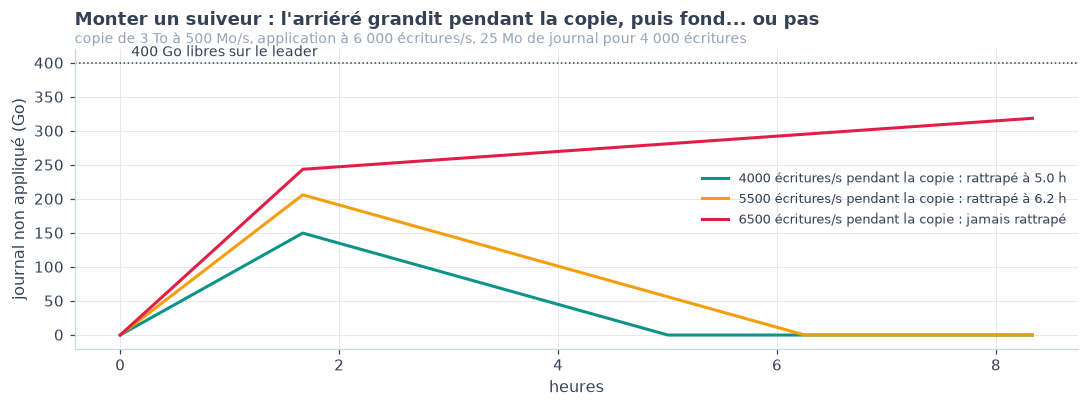

In [3]:
def operation(lam_copie, lam_apres=4000, mu=6000, Tc=6000, horizon=30000, mo_par_ecriture=25 / 4000):
    arr, out = 0.0, []
    for t in range(horizon):
        if t < Tc:
            arr += lam_copie
        else:
            arr = max(0.0, arr + lam_apres - mu)
        out.append(arr)
    out = np.array(out)
    fin = np.argmax((np.arange(horizon) > Tc) & (out == 0)) if (out[Tc:] == 0).any() else None
    return out, out * mo_par_ecriture / 1000, fin

fig, ax = plt.subplots(figsize=(10, 3.8))
for lam, c in [(4000, TEAL), (5500, AMBER), (6500, ROSE)]:
    arr, go, fin = operation(lam, lam_apres=lam if lam > 6000 else 4000)
    ax.plot(np.arange(len(go)) / 3600, go, color=c,
            label=f"{lam} écritures/s pendant la copie : " + (f"rattrapé à {fin / 3600:.1f} h" if fin else "jamais rattrapé"))
ax.axhline(400, color=SLATE, ls=":", lw=1); ax.text(0.1, 410, "400 Go libres sur le leader", fontsize=9)
ax.set_xlabel("heures"); ax.set_ylabel("journal non appliqué (Go)")
ax.set_title("Monter un suiveur : l'arriéré grandit pendant la copie, puis fond... ou pas")
subtitle(ax, "copie de 3 To à 500 Mo/s, application à 6 000 écritures/s, 25 Mo de journal pour 4 000 écritures")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

La simulation retrouve 5 h au total pour la charge nominale, 6,2 h avec le pic à 5 500,
et une croissance sans fin à 6 500 : 244 Go à la fin de la copie, puis 500 écritures/s de
plus chaque seconde, et les 400 Go seraient dépassés au bout d'une quinzaine d'heures.

> **À retenir.** Monter un suiveur dure le temps de la copie **plus** un rattrapage
> inversement proportionnel à la marge $\mu - \lambda$ ; sans marge, il ne rattrape jamais
> et le journal remplit le disque du leader.

## Exercice 5.3 : régler le délai de basculement, et l'anomalie du basculement

**Énoncé.** *Partie A.* Le contrôleur reçoit un battement par seconde. Mesures : l'écart
entre deux battements dépasse $T$ secondes avec une probabilité $P(G > T) \approx 0{,}2
\, e^{-(T-1)/2}$ pour $T \ge 1$ (pics de charge, pauses).

1. Combien de basculements inutiles par an pour $T = 5$, 10, 20 et 30 s ?
2. Une vraie panne du leader se produit deux fois par an ; un basculement coûte $T + 15$ s
   d'indisponibilité ; un basculement inutile coûte 15 s et a 5 % de chances de causer
   un incident d'une heure. Quel $T$ minimise l'indisponibilité annuelle attendue ?

*Partie B.* Scénario : la base (réplication asynchrone) attribue des clés primaires
auto-incrémentées ; un service de facturation lit chaque nouvelle commande sur le leader
et envoie la facture par courriel, identifiée par le numéro de commande. Le leader tombe,
un suiveur en retard de 3 commandes est promu. Décrivez précisément l'anomalie et deux
parades.

**Rappels.** Le délai d'expiration arbitre entre reprise lente et basculements inutiles ;
un basculement asynchrone jette les écritures que le leader était seul à avoir, ce qui
peut casser les systèmes externes (incident GitHub, cours 1, sections 5 et 6, section
*Leader failure: Failover*).

**Solution.**

*A.1.* Avec 31,5 millions de battements par an, le nombre de dépassements vaut
$3{,}15 \cdot 10^7 \times 0{,}2\, e^{-(T-1)/2}$ : environ 850 000 pour 5 s, 70 000 pour
10 s, 470 pour 20 s et 3 pour 30 s (tableau ci-dessous). Un seul dépassement suffit à
déclencher un basculement.

*A.2.* Indisponibilité annuelle $= 2 (T + 15) + F(T) \times (15 + 0{,}05 \times 3\,600)$
secondes, où $F(T)$ est le nombre de basculements inutiles. Le premier terme croît
linéairement, le second décroît exponentiellement : l'optimum est là où ils se
compensent. À 30 s, il reste 3 fausses alertes par an (10 minutes d'indisponibilité) ;
à 40 s, 0,1 par an, pour 110 s de vraies pannes : l'optimum est vers 40 s. L'ordre de
grandeur de 30 s cité par le livre n'est pas un hasard.

*B.* Les commandes 101 à 103, validées sur l'ancien leader, n'existent pas sur le nouveau,
dont le compteur repart à 101. Les **nouvelles** commandes 101 à 103, d'autres clients,
reçoivent des numéros déjà utilisés dans des factures envoyées : le client de l'ancienne
commande 101 peut recevoir des relances pour la commande de quelqu'un d'autre, et la
comptabilité a deux factures pour un même numéro. Parades : (1) clés non réutilisables
(UUID, ou identifiants incluant l'époque du leader) ; (2) ne laisser le service externe
agir que sur des écritures **répliquées** (lire sur un suiveur synchrone, ou attendre
que la position du journal soit acquittée par un quorum) ; (3) réplication
semi-synchrone avec promotion du suiveur synchrone.

**Vérification numérique.**

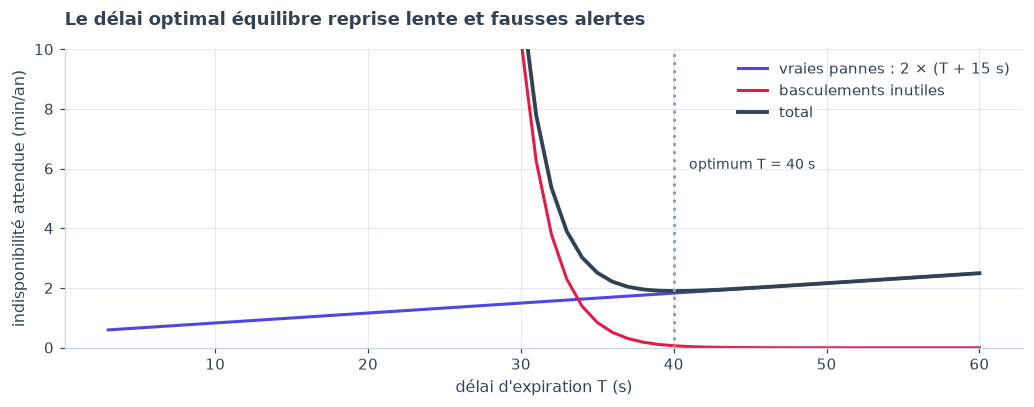

T (s),5,10,20,30
basculements inutiles / an,852612.28,69986.68,471.57,3.18


In [4]:
T = np.arange(3, 61)
F = 3.15e7 * 0.2 * np.exp(-(T - 1) / 2)
indispo = 2 * (T + 15) + F * (15 + 0.05 * 3600)
best = T[np.argmin(indispo)]
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(T, 2 * (T + 15) / 60, color=INDIGO, label="vraies pannes : 2 × (T + 15 s)")
ax.plot(T, F * (15 + 180) / 60, color=ROSE, label="basculements inutiles")
ax.plot(T, indispo / 60, color=SLATE, lw=2.5, label="total")
ax.axvline(best, color=GRAY, ls=":"); ax.text(best + 1, 6, f"optimum T = {best} s", fontsize=9)
ax.set_ylim(0, 10); ax.set_xlabel("délai d'expiration T (s)"); ax.set_ylabel("indisponibilité attendue (min/an)")
ax.set_title("Le délai optimal équilibre reprise lente et fausses alertes")
ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame({"T (s)": [5, 10, 20, 30], "basculements inutiles / an": [3.15e7 * 0.2 * math.exp(-(t - 1) / 2) for t in [5, 10, 20, 30]]}).set_index("T (s)").T.round(2)

Le minimum tombe vers 40 s, pour un peu moins de 2 minutes d'indisponibilité par an ; en
dessous de 30 s, les fausses alertes dominent brutalement. Rejouons ensuite l'anomalie de la
partie B avec la mini-base.

In [5]:
leader, suiveur = rp.MiniDB("leader"), rp.MiniDB("suiveur")
factures = []
for i in range(103):
    pk = leader.insert("commandes", {"client": f"client{i}"})
    factures.append((pk, f"client{i}"))
    if i < 100:
        suiveur.apply_change(leader.changes[-1])
for j in range(3):
    pk = suiveur.insert("commandes", {"client": f"nouveau{j}"})
    factures.append((pk, f"nouveau{j}"))
F_ = pd.DataFrame(factures, columns=["numéro", "client facturé"])
F_[F_["numéro"].duplicated(keep=False)].sort_values("numéro")

,numéro,client facturé
100,101,client100
103,101,nouveau0
101,102,client101
104,102,nouveau1
102,103,client102
105,103,nouveau2


> **À retenir.** Le délai de basculement se règle sur la distribution mesurée des
> silences, pas au jugé ; et toute écriture qu'un système externe a vue avant qu'elle soit
> répliquée peut devenir incohérente après un basculement.